# P4. 분포끼리 비교하기: 그림, 요약값, 검정, 효과 크기, p 값의 뜻

**목표**
- 두 분포가 "다르다"는 말이 어떤 뜻들(중심, 퍼짐, 모양, 꼬리)을 가질 수 있는지 그림으로 구분합니다.
- 요약값·그림·검정이 각각 무엇을 보고 무엇을 놓치는지 직접 확인합니다.
- p 값이 실제로 무엇을 재는지 시뮬레이션으로 만들어 보고, 효과 크기·보정 전후 비교·다중 검정까지 연결합니다.

**이 노트북이 답하는 질문**: 두 군(예: 두 배치, 두 나이군)의 깊이나 VAF 분포를 비교할 때, 무엇을 그리고 무엇을 계산해야 오해 없이 "다르다/같다"를 말할 수 있나요?

**같이 볼 교재**

| 이 노트북 | OpenIntro Statistics (무료 교재) [1] | 그 밖에 |
|---|---|---|
| 요약값, 그림(히스토그램·상자 그림) | Chapter 2 Summarizing Data | Blitzstein & Hwang 6장 "Summaries of a distribution" [2] |
| 가설 검정, p 값 | Chapter 5 Foundations for Inference (5.3 Hypothesis testing) | – |
| 두 평균의 차이 | Chapter 7 Inference for Numerical Data (7.3 Difference of two means, 7.4 Power calculations) | Welch 1947 [4] |
| 순위 검정, KS, 순열 검정, 다중 검정 | – | SciPy 문서 [3], Mann & Whitney 1947 [5], Benjamini & Hochberg 1995 [7] |

In [1]:
# ---- common start (study_build/stats/_common_p14.py 에서 복사; 고칠 땐 그 파일을 고치고 sync_common.py) ----
# 그림 도구입니다. 펼치지 않아도 됩니다. 팔레트: Okabe-Ito, 색의 뜻은 고정(STYLE §1-3).
import logging, math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle, FancyArrowPatch
from scipy import stats

COL = dict(prior="#56B4E9", likelihood="#E69F00", posterior="#0072B2", evidence="#374151",
           A="#0072B2", B="#E69F00", part="#56B4E9", g1="#0072B2", g2="#E69F00",
           sim="#D1D5DB", simedge="#9CA3AF", theory="#222222", null="#9CA3AF",
           highlight="#CC79A7", ok="#009E73", ink="#222222", muted="#6B7280",
           grid="#E5E7EB", none="#E5E7EB", shade="#F3F4F6")
RAMP = ["#C3CAD4", "#98A2B0", "#6B7280", "#3F4652", "#111827"]   # 순서 있는 값(옅음 → 진함)

def apply_theme():
    logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # 글꼴 대체 경고 숨김
    plt.rcParams.update({
        "font.family": ["Arial", "DejaVu Sans"], "font.size": 10.5, "mathtext.fontset": "dejavusans",
        "axes.titlesize": 11.5, "axes.titleweight": "semibold", "axes.titlelocation": "left",
        "axes.titlepad": 10, "axes.labelsize": 10.5, "axes.labelcolor": COL["ink"],
        "axes.edgecolor": "#9CA3AF", "axes.linewidth": 0.8,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": False, "grid.color": COL["grid"], "grid.linewidth": 0.8,
        "xtick.color": COL["muted"], "ytick.color": COL["muted"],
        "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
        "legend.frameon": False, "legend.fontsize": 9.5,
        "figure.dpi": 110, "savefig.bbox": "tight", "figure.facecolor": "white"})

def panel(ax, letter, title, **kw):
    """왼쪽 정렬 'A   제목' 형식의 패널 제목"""
    ax.set_title(f"{letter}   {title}" if letter else title, **kw)

def note(ax, x, y, text, **kw):
    """회색 작은 주석"""
    kw.setdefault("fontsize", 9); kw.setdefault("color", COL["muted"])
    return ax.text(x, y, text, **kw)

def callout(ax, x, y, text, **kw):
    """핵심 메시지 한 줄: 자주색 굵은 글씨 + 흰 바탕"""
    kw.setdefault("fontsize", 10); kw.setdefault("color", COL["highlight"]); kw.setdefault("fontweight", "semibold")
    kw.setdefault("bbox", dict(facecolor="white", edgecolor="none", pad=1.5, alpha=0.9))
    return ax.text(x, y, text, **kw)

def ygrid(ax):
    ax.yaxis.grid(True); ax.set_axisbelow(True)

def formula_strip(ax, parts, y=0.5, fontsize=17, gap=0.012):
    """수식을 조각(chip)으로 그린다. parts = [(mathtext, color 또는 None, 아래 이름표 또는 None), ...]
    색이 있는 조각은 옅은 배경 상자 + 같은 색 이름표. 그림의 같은 색과 짝을 이룬다."""
    ax.set_axis_off(); fig = ax.figure
    r = fig.canvas.get_renderer(); inv = ax.transAxes.inverted(); items = []
    for tex, color, label in parts:                        # 조각과 이름표 중 넓은 쪽을 칸 폭으로
        t = ax.text(0, y, tex, fontsize=fontsize, va="center", ha="center",
                    color=color or COL["ink"], transform=ax.transAxes)
        bb = t.get_window_extent(renderer=r).transformed(inv)
        lw = 0.0
        if label:
            tl = ax.text(0, 0, label, fontsize=9.5, fontweight="semibold", transform=ax.transAxes)
            lw = tl.get_window_extent(renderer=r).transformed(inv).width; tl.remove()
        items.append((t, bb, color, label, max(bb.width, lw)))
    total = sum(w for *_, w in items) + gap * (len(items) - 1)
    x = (1 - total) / 2                                    # 가운데 정렬
    for t, bb, color, label, w in items:
        cx = x + w / 2; t.set_x(cx); x += w + gap
        if color:
            ax.add_patch(FancyBboxPatch((cx - bb.width / 2 - 0.006, bb.y0 - 0.04), bb.width + 0.012, bb.height + 0.08,
                                        boxstyle="round,pad=0,rounding_size=0.02", transform=ax.transAxes,
                                        facecolor=color, alpha=0.13, edgecolor="none", zorder=0))
        if label:
            ax.text(cx, bb.y0 - 0.12, label, ha="center", va="top", fontsize=9.5,
                    color=color or COL["muted"], fontweight="semibold", transform=ax.transAxes)

def concept_map(nodes, edges, figsize=(11, 3.4), title=None, box=(0.13, 0.2), label_dy=0.05):
    """개념 지도. nodes = {키: (x, y, '글자', 색 또는 None)}, edges = [(키1, 키2, '화살표 글자' 또는 '')].
    좌표는 0~1. 색이 있는 상자는 그 색의 옅은 바탕."""
    fig, ax = plt.subplots(figsize=figsize); ax.set_axis_off(); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    w, h = box
    for k, (x, y, label, color) in nodes.items():
        ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.01,rounding_size=0.03",
                                    facecolor=(color or COL["shade"]), alpha=0.22 if color else 1.0,
                                    edgecolor=(color or "#9CA3AF"), lw=1.2))
        ax.text(x, y, label, ha="center", va="center", fontsize=9.5, color=COL["ink"])
    for a, b, label in edges:
        (x1, y1), (x2, y2) = nodes[a][:2], nodes[b][:2]
        ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=12, color="#6B7280",
                                     lw=1.1, shrinkA=38, shrinkB=38, connectionstyle="arc3,rad=0.0"))
        if label:
            vertical = abs(x2 - x1) < 0.03
            ax.text((x1 + x2) / 2 + (0.012 if vertical else 0), (y1 + y2) / 2 + (0 if vertical else label_dy), label,
                    ha="left" if vertical else "center", va="center" if vertical else "bottom", fontsize=8.5,
                    color=COL["muted"], bbox=dict(facecolor="white", edgecolor="none", pad=0.5))
    if title:
        ax.text(0, 1.02, title, fontsize=11.5, fontweight="semibold", transform=ax.transAxes, va="bottom")
    return fig

apply_theme()
# ---- common end ----

rng0 = np.random.default_rng(40)

def bimodal(n, a=0.67, s=0.3, rng=rng0):
    """중앙값 0, 사분위 범위가 표준정규와 거의 같은 쌍봉 분포"""
    return np.where(rng.random(n) < 0.5, -a, a) + rng.normal(0, s, n)

def draw_concept_map():
    nodes = {"S": (0.075, 0.5, "two samples", None),
             "W": (0.235, 0.84, "how can they\ndiffer?", None),
             "Su": (0.235, 0.16, "summaries\nmean, median, IQR", None),
             "Pi": (0.405, 0.5, "pictures\nbox, ECDF, QQ", COL["A"]),
             "T": (0.585, 0.84, "tests\nt, rank, KS", None),
             "Pv": (0.585, 0.16, "what a\np-value means", None),
             "E": (0.765, 0.5, "effect size\nhow big", COL["B"]),
             "Ad": (0.925, 0.84, "adjusted and\nunadjusted", None),
             "M": (0.925, 0.16, "many tests\nFDR", None)}
    edges = [("S", "W", ""), ("S", "Su", ""), ("W", "Pi", ""), ("Su", "Pi", ""), ("Pi", "T", ""), ("Pi", "Pv", ""),
             ("T", "E", ""), ("Pv", "E", ""), ("E", "Ad", ""), ("E", "M", "")]
    return concept_map(nodes, edges, title="Concept map: comparing two distributions")

def draw_four_differences():
    g = np.linspace(-5, 5, 500)
    t3 = stats.t(3); t3s = 1 / t3.std()
    cases = [("A", "Centre differs (shift)", stats.norm.pdf(g), stats.norm.pdf(g, 1, 1)),
             ("B", "Spread differs (scale)", stats.norm.pdf(g), stats.norm.pdf(g, 0, 1.8)),
             ("C", "Shape differs (one peak vs two)", stats.norm.pdf(g),
              0.5 * stats.norm.pdf(g, -0.67, 0.3) + 0.5 * stats.norm.pdf(g, 0.67, 0.3)),
             ("D", "Tails differ (same SD)", stats.norm.pdf(g), t3.pdf(g / t3s) / t3s)]
    fig, ax = plt.subplots(2, 2, figsize=(11, 5.6), sharex=True)
    for a, (L, title, f1, f2) in zip(ax.ravel(), cases):
        a.fill_between(g, f1, color=COL["g1"], alpha=0.25, lw=0); a.plot(g, f1, color=COL["g1"], lw=1.4)
        a.plot(g, f2, color=COL["g2"], lw=2.0)
        panel(a, L, title); ygrid(a); a.set_ylim(0, max(f1.max(), f2.max()) * 1.18)
    note(ax[0, 0], -4.8, 0.36, "blue fill: group 1\norange line: group 2", va="top", fontsize=9.5, color=COL["ink"])
    callout(ax[1, 1], 4.9, 0.68, "heavier tails, same mean and SD", ha="right", va="top")
    ins = ax[1, 1].inset_axes([0.66, 0.2, 0.31, 0.42])          # 꼬리만 로그 눈금으로 확대
    gt = np.linspace(1.5, 5, 200)
    ins.semilogy(gt, stats.norm.pdf(gt), color=COL["g1"], lw=1.4); ins.semilogy(gt, t3.pdf(gt / t3s) / t3s, color=COL["g2"], lw=1.8)
    ins.set_title("tails, log scale", fontsize=8.5, pad=2); ins.tick_params(labelsize=7.5)
    for sp in ("top", "right"):
        ins.spines[sp].set_visible(False)
    callout(ax[1, 0], 4.9, 0.62, "same mean and median", ha="right", va="top")
    for a in ax[1]:
        a.set_xlabel("value")
    fig.tight_layout()
    return fig

def draw_robust():
    x = np.array([28, 30, 31, 31, 32, 33, 34, 35, 36, 38], float)
    xo = np.append(x, 120.0)
    fig, ax = plt.subplots(2, 1, figsize=(10, 4.4), sharex=True, gridspec_kw={"hspace": 0.6})
    for a, d, L, t in [(ax[0], x, "A", "10 windows"), (ax[1], xo, "B", "same 10 windows + one 120x window")]:
        a.scatter(d, np.zeros_like(d), s=60, color=COL["sim"], edgecolors=COL["simedge"], zorder=3)
        mu, med = d.mean(), np.median(d)
        a.axvline(mu, color=COL["g2"], lw=2); a.axvline(med, color=COL["g1"], lw=2, ls=(0, (4, 2)))
        a.text(mu + 0.8, 0.55, f"mean {mu:.1f}", color="#B7791F", fontsize=10)
        a.text(med - 0.8, 0.55, f"median {med:.1f}", color=COL["g1"], fontsize=10, ha="right")
        q1, q3 = np.percentile(d, [25, 75]); mad = np.median(np.abs(d - med))
        note(a, 125, -0.75, f"SD {d.std(ddof=1):.1f}   IQR {q3 - q1:.1f}   MAD {mad:.1f}", ha="right", va="center", color=COL["ink"], fontsize=9.5)
        a.set_ylim(-1, 1); a.set_yticks([]); a.spines["left"].set_visible(False)
        panel(a, L, t)
    ax[1].set_xlabel("depth (x)"); ax[1].set_xlim(25, 127)
    callout(ax[1], 80, 0.55, "one outlier drags the mean, not the median", ha="center")
    return fig, (x.mean(), xo.mean(), np.median(x), np.median(xo))

def draw_four_pictures(n=400, seed=41):
    rng = np.random.default_rng(seed)
    a1 = rng.normal(0, 1, n); a2 = bimodal(n, rng=rng)
    fig, ax = plt.subplots(2, 2, figsize=(11, 7.4))
    a = ax[0, 0]
    bp = a.boxplot([a1, a2], positions=[0.85, 1.85], widths=0.3, patch_artist=True, showfliers=False,
                   medianprops=dict(color=COL["ink"], lw=1.6))
    for patch, c in zip(bp["boxes"], [COL["g1"], COL["g2"]]):
        patch.set_facecolor(c); patch.set_alpha(0.3); patch.set_edgecolor(c)
    for i, (d, c) in enumerate([(a1, COL["g1"]), (a2, COL["g2"])], 1):
        a.scatter(i + 0.25 + rng.uniform(-0.09, 0.09, n), d, s=4, color=c, alpha=0.55, linewidths=0)
    a.set_xticks([1, 2], ["group 1", "group 2"]); ygrid(a); a.set_ylabel("value")
    callout(a, 1.5, 3.2, "middle 50% boxes look alike", ha="center")
    note(a, 2.25, -2.9, "points: few\nnear 0", ha="center", color="#B7791F")
    panel(a, "A", "Box (left) + points (right): the box hides the two peaks")
    a = ax[0, 1]
    bins = np.linspace(-3.5, 3.5, 36)
    a.hist(a1, bins=bins, density=True, color=COL["g1"], alpha=0.35)
    a.hist(a2, bins=bins, density=True, histtype="step", color=COL["g2"], lw=2)
    ygrid(a); a.set_xlabel("value"); a.set_ylabel("density")
    callout(a, 3.4, 0.68, "two peaks", ha="right", va="top")
    panel(a, "B", "Histograms: shape is visible")
    a = ax[1, 0]
    for d, c in [(a1, COL["g1"]), (a2, COL["g2"])]:
        xs = np.sort(d); a.step(xs, np.arange(1, n + 1) / n, where="post", color=c, lw=1.8)
    ygrid(a); a.set_xlabel("value"); a.set_ylabel("share <= value")
    note(a, -3.3, 0.9, "group 1 (blue)\ngroup 2 (orange)", va="top", color=COL["ink"], fontsize=9.5)
    callout(a, 3.3, 0.3, "they meet in the middle\nbut part ways around it", ha="right", va="center")
    panel(a, "C", "ECDF: every value at once")
    a = ax[1, 1]
    q = np.linspace(0.01, 0.99, 99)
    a.plot(np.quantile(a1, q), np.quantile(a2, q), "o", color=COL["evidence"], ms=3.5)
    lim = [-2.6, 2.6]; a.plot(lim, lim, color=COL["muted"], lw=1, ls=":")
    a.set_xlim(lim); a.set_ylim(lim); a.set_aspect("equal"); ygrid(a)
    a.set_xlabel("group 1 quantile"); a.set_ylabel("group 2 quantile")
    callout(a, 2.5, -2.3, "steep middle, flat ends:\ntwo peaks, short tails", ha="right", va="bottom")
    panel(a, "D", "QQ plot: quantile against quantile")
    fig.tight_layout()
    return fig, a1, a2

def ecdf(d, x):
    return np.searchsorted(np.sort(d), x, side="right") / len(d)

def draw_ecdf_ks(a1, a2):
    fig = plt.figure(figsize=(11, 5.6))
    gs = fig.add_gridspec(2, 1, height_ratios=[0.9, 4], hspace=0.45)
    axf = fig.add_subplot(gs[0])
    formula_strip(axf, [(r"$\hat F(x)$", COL["g1"], "ECDF"), (r"$=$", None, None),
                        (r"$\frac{1}{n}$", COL["muted"], "share of"), (r"$\sum_i \mathbf{1}[x_i \leq x]$", COL["evidence"], "points at or below x"),
                        (r"$\quad D = \max_x |\hat F_1(x) - \hat F_2(x)|$", COL["highlight"], "KS: the biggest gap")])
    a = fig.add_subplot(gs[1])
    grid = np.sort(np.concatenate([a1, a2]))
    f1, f2 = ecdf(a1, grid), ecdf(a2, grid)
    i = np.argmax(np.abs(f1 - f2)); D = abs(f1[i] - f2[i])
    a.step(grid, f1, where="post", color=COL["g1"], lw=1.8); a.step(grid, f2, where="post", color=COL["g2"], lw=1.8)
    a.annotate("", xy=(grid[i], f2[i]), xytext=(grid[i], f1[i]), arrowprops=dict(arrowstyle="<->", color=COL["highlight"], lw=2))
    callout(a, grid[i] + 0.12, (f1[i] + f2[i]) / 2, f"D = {D:.3f}", va="center")
    ygrid(a); a.set_xlabel("value"); a.set_ylabel("share <= value")
    panel(a, "", "Kolmogorov-Smirnov statistic = the largest vertical gap between ECDFs")
    return fig, D

def draw_qq_patterns(n=2000, seed=42):
    rng = np.random.default_rng(seed); q = np.linspace(0.01, 0.99, 99)
    base = rng.normal(0, 1, n)
    t3 = stats.t(3)
    cases = [("A", "shift: parallel above", rng.normal(1, 1, n)),
             ("B", "wider: steeper line", rng.normal(0, 1.8, n)),
             ("C", "heavier tails: ends bend out", t3.rvs(n, random_state=rng) / t3.std()),
             ("D", "right skew: bends up", rng.exponential(1, n) - 1)]
    fig, ax = plt.subplots(1, 4, figsize=(12.5, 3.5))
    for a, (L, t, d) in zip(ax, cases):
        a.plot(np.quantile(base, q), np.quantile(d, q), "o", color=COL["g2"], ms=3)
        lim = [-3.2, 4.2]; a.plot(lim, lim, color=COL["muted"], lw=1, ls=":")
        a.set_xlim(lim); a.set_ylim(lim); a.set_aspect("equal"); ygrid(a)
        panel(a, L, t); a.set_xlabel("group 1 (normal)")
    ax[0].set_ylabel("group 2 quantile")
    note(ax[0], -3.0, 3.9, "dotted: y = x\n(identical)", va="top")
    fig.tight_layout()
    return fig

def welch_t(x, y):
    vx, vy = x.var(ddof=1) / len(x), y.var(ddof=1) / len(y)
    return (x.mean() - y.mean()) / np.sqrt(vx + vy)

def draw_permutation(n=30, shift=0.6, n_perm=10000, seed=43):
    rng = np.random.default_rng(seed)
    x = rng.normal(shift, 1, n); y = rng.normal(0, 1, n)
    obs = x.mean() - y.mean()
    pooled = np.concatenate([x, y])
    idx = np.argsort(rng.random((n_perm, 2 * n)), axis=1)
    perm = pooled[idx]; null = perm[:, :n].mean(1) - perm[:, n:].mean(1)
    p_perm = (np.sum(np.abs(null) >= abs(obs)) + 1) / (n_perm + 1)
    p_welch = stats.ttest_ind(x, y, equal_var=False).pvalue
    fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.3), gridspec_kw={"width_ratios": [1, 1.7]})
    a = ax[0]
    a.scatter(np.zeros(n) + rng.uniform(-0.12, 0.12, n), x, s=22, color=COL["g1"])
    a.scatter(np.ones(n) + rng.uniform(-0.12, 0.12, n), y, s=22, color=COL["g2"])
    for i, d, c in [(0, x, COL["g1"]), (1, y, COL["g2"])]:
        a.hlines(d.mean(), i - 0.3, i + 0.3, color=c, lw=2.2)
    a.set_xticks([0, 1], ["group 1", "group 2"]); a.set_xlim(-0.6, 1.6); ygrid(a)
    callout(a, 0.5, max(x.max(), y.max()) + 0.1, f"difference in means = {obs:.2f}", ha="center", va="bottom")
    a.set_ylim(min(x.min(), y.min()) - 0.4, max(x.max(), y.max()) + 0.8)
    panel(a, "A", f"Observed data (n = {n} each)")
    a = ax[1]
    a.hist(null, bins=60, color=COL["null"], alpha=0.6, edgecolor="white", lw=0.3)
    tail = np.abs(null) >= abs(obs)
    a.hist(null[tail], bins=60, range=(null.min(), null.max()), color=COL["evidence"], alpha=0.9)
    a.axvline(obs, color=COL["ink"], lw=1.6); a.axvline(-obs, color=COL["ink"], lw=1, ls=":")
    a.text(obs + 0.02, a.get_ylim()[1] * 0.9, "observed", fontsize=9.5)
    callout(a, 0.02, 0.95, f"dark share = p = {p_perm:.4f}\n(Welch t-test: {p_welch:.4f})", ha="left", va="top", transform=a.transAxes)
    ygrid(a); a.set_xlabel("difference in means after shuffling the group labels")
    panel(a, "B", "Null distribution: what 'no difference' looks like")
    fig.tight_layout()
    return fig, p_perm, p_welch

def draw_power(n=50, reps=300, seed=44, n_perm=999):
    rng = np.random.default_rng(seed)
    t3 = stats.t(3)
    scen = [("no difference", lambda: (rng.normal(0, 1, n), rng.normal(0, 1, n))),
            ("shift 0.6 SD", lambda: (rng.normal(0.6, 1, n), rng.normal(0, 1, n))),
            ("wider x2", lambda: (rng.normal(0, 2, n), rng.normal(0, 1, n))),
            ("two peaks", lambda: (bimodal(n, a=1.0, s=0.3, rng=rng), rng.normal(0, np.sqrt(1.09), n)))]
    tests = ["Welch t", "Mann-Whitney", "KS", "permutation\n(mean)"]
    R = np.zeros((len(tests), len(scen)))
    for j, (_, gen) in enumerate(scen):
        hits = np.zeros(len(tests))
        for _ in range(reps):
            x, y = gen()
            p = [stats.ttest_ind(x, y, equal_var=False).pvalue, stats.mannwhitneyu(x, y).pvalue, stats.ks_2samp(x, y).pvalue]
            pooled = np.concatenate([x, y]); idx = np.argsort(rng.random((n_perm, 2 * n)), axis=1)
            pm = pooled[idx]; null = pm[:, :n].mean(1) - pm[:, n:].mean(1)
            p.append((np.sum(np.abs(null) >= abs(x.mean() - y.mean())) + 1) / (n_perm + 1))
            hits += np.array(p) < 0.05
        R[:, j] = hits / reps
    fig, ax = plt.subplots(figsize=(9.5, 4.2))
    for i in range(len(tests)):
        for j in range(len(scen)):
            v = R[i, j]
            ax.scatter(j, i, s=2200 * v + 40, color=COL["evidence"] if (j > 0 and v > 0.3) else RAMP[1], alpha=0.85, linewidths=0)
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=10, color="white" if v > 0.3 else COL["ink"], fontweight="semibold")
    ax.set_xticks(range(len(scen)), [s for s, _ in scen]); ax.set_yticks(range(len(tests)), tests)
    ax.set_xlim(-0.6, len(scen) - 0.4); ax.set_ylim(len(tests) - 0.5, -0.5)
    for s in ("left", "bottom"):
        ax.spines[s].set_visible(False)
    ax.tick_params(length=0)
    ax.set_title(f"How often each test says p < 0.05 ({reps} simulated studies, n = {n} per group)")
    note(ax, -0.55, 3.75, "first column should be about 5% (false alarms); dark circles = a real difference caught in more than 30% of studies", va="top")
    fig.tight_layout()
    return fig, R

def cohens_d(x, y):
    sp = np.sqrt(((len(x) - 1) * x.var(ddof=1) + (len(y) - 1) * y.var(ddof=1)) / (len(x) + len(y) - 2))
    return (x.mean() - y.mean()) / sp

def draw_p_vs_effect(d=0.05, seed=45):
    rng = np.random.default_rng(seed)
    ns = np.unique(np.geomspace(20, 200000, 18).astype(int))
    ps, ds = [], []
    for n in ns:
        x = rng.normal(d, 1, n); y = rng.normal(0, 1, n)
        ps.append(stats.ttest_ind(x, y, equal_var=False).pvalue); ds.append(cohens_d(x, y))
    fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.2))
    a = ax[0]
    a.loglog(ns, ps, "o-", color=COL["ink"], ms=4, lw=1)
    a.axhline(0.05, color=COL["muted"], ls=(0, (4, 2)), lw=1.2)
    a.text(25, 0.03, "p = 0.05", color=COL["muted"], fontsize=9.5, va="top")
    a.set_xlabel("n per group (log)"); a.set_ylabel("p-value (log)"); a.grid(True, color=COL["grid"])
    a2 = a.twinx(); a2.semilogx(ns, ds, "s", markerfacecolor="white", markeredgecolor=COL["evidence"], ms=5); a2.set_ylim(-0.4, 0.4)
    a2.set_ylabel("Cohen's d (open squares)", color=COL["evidence"]); a2.spines["right"].set_visible(True)
    callout(a, 0.03, 0.06, "p keeps shrinking; the effect stays tiny (d = 0.05)", va="bottom", transform=a.transAxes)
    panel(a, "A", "Same tiny effect, growing sample")
    a = ax[1]
    n = 50000; x = rng.normal(d, 1, n); y = rng.normal(0, 1, n)
    bins = np.linspace(-4, 4, 60)
    a.hist(y, bins=bins, density=True, color=COL["g2"], alpha=0.35); a.hist(x, bins=bins, density=True, histtype="step", color=COL["g1"], lw=1.6)
    U = stats.mannwhitneyu(x, y).statistic; auc = U / (n * n)
    p = stats.ttest_ind(x, y, equal_var=False).pvalue
    note(a, 0.98, 0.95, f"n = {n:,} per group\np = {p:.1e}\nCohen's d = {cohens_d(x, y):.3f}\nmedian difference = {np.median(x) - np.median(y):.3f}\nAUC = P(X > Y) = {auc:.3f}",
         ha="right", va="top", transform=a.transAxes, color=COL["ink"], fontsize=9.5)
    callout(a, 0.02, 0.95, "'significant'\nbut nearly\nidentical", va="top", transform=a.transAxes)
    ygrid(a); a.set_xlabel("value")
    panel(a, "B", f"What p = {p:.1e} can look like")
    fig.tight_layout()
    return fig, auc, cohens_d(x, y)

def draw_confounding(seed=46):
    rng = np.random.default_rng(seed)
    nA, nB = 120, 120
    batchA = rng.random(nA) < 0.8           # 군 A 는 80% 가 배치 2
    batchB = rng.random(nB) < 0.2           # 군 B 는 20% 만 배치 2
    yA = 30 + 6 * batchA + rng.normal(0, 3, nA)   # 배치 2 는 깊이가 6 높음, 군 효과는 0
    yB = 30 + 6 * batchB + rng.normal(0, 3, nB)
    def diff_ci(x, y):
        d = x.mean() - y.mean(); se = np.sqrt(x.var(ddof=1) / len(x) + y.var(ddof=1) / len(y)); return d, d - 1.96 * se, d + 1.96 * se
    un = diff_ci(yA, yB)
    within = [diff_ci(yA[batchA == b], yB[batchB == b]) for b in (False, True)]
    w = np.array([1 / ((w_[2] - w_[1]) / 3.92) ** 2 for w_ in within])
    est = (w * np.array([w_[0] for w_ in within])).sum() / w.sum(); se = 1 / np.sqrt(w.sum())
    adj = (est, est - 1.96 * se, est + 1.96 * se)
    fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.3), gridspec_kw={"width_ratios": [1.2, 1]})
    a = ax[0]
    for i, (yy, bb, c) in enumerate([(yA, batchA, COL["g1"]), (yB, batchB, COL["g2"])]):
        xj = i + rng.uniform(-0.18, 0.18, len(yy))
        a.scatter(xj[~bb], yy[~bb], s=16, facecolors="none", edgecolors=c, linewidths=1)
        a.scatter(xj[bb], yy[bb], s=16, color=c, linewidths=0)
    a.set_xticks([0, 1], ["group A\n(80% batch 2)", "group B\n(20% batch 2)"]); ygrid(a); a.set_ylabel("depth")
    note(a, 1.45, yA.max(), "filled = batch 2\nopen = batch 1", ha="right", va="top", color=COL["ink"], fontsize=9.5)
    panel(a, "A", "Batch 2 runs deeper; group A is mostly batch 2")
    a = ax[1]
    rows = [("unadjusted", un, COL["evidence"]), ("within batch 1", within[0], RAMP[2]),
            ("within batch 2", within[1], RAMP[2]), ("adjusted for batch", adj, COL["ink"])]
    for k, (lab, (d, lo, hi), c) in enumerate(rows):
        a.plot([lo, hi], [k, k], color=c, lw=2.2); a.scatter([d], [k], s=60, color=c, zorder=3)
        a.text(hi + 0.25, k, f"{d:+.1f}", va="center", fontsize=9.5, color=c)
    a.axvline(0, color=COL["muted"], lw=1, ls=":")
    a.set_yticks(range(len(rows)), [r[0] for r in rows]); a.set_ylim(len(rows) - 0.5, -0.5)
    a.set_xlabel("difference A - B in mean depth (95% CI)"); a.xaxis.grid(True); a.set_axisbelow(True)
    callout(a, 0.98, 0.04, "the 'group difference' was batch", ha="right", va="bottom", transform=a.transAxes)
    panel(a, "B", "Show both numbers")
    fig.tight_layout()
    return fig, un[0], adj

def draw_bh(m=1000, m1=100, q=0.05, seed=47, n=20):
    rng = np.random.default_rng(seed)
    truth = np.zeros(m, bool); truth[:m1] = True
    x = rng.normal(np.where(truth, 1.0, 0.0)[:, None], 1, (m, n)); y = rng.normal(0, 1, (m, n))
    p = stats.ttest_ind(x, y, axis=1, equal_var=False).pvalue
    raw = p < 0.05
    adj = stats.false_discovery_control(p, method="bh"); bh = adj < q
    order = np.argsort(p); ps = p[order]; k = np.arange(1, m + 1)
    fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.2))
    a = ax[0]
    a.hist([p[truth], p[~truth]], bins=40, range=(0, 1), stacked=True, color=[COL["g1"], COL["null"]])
    ygrid(a); a.set_xlabel("p-value"); a.set_ylabel("tests")
    note(a, 0.98, 0.95, "stacked bars, grey on top:\ngrey: 900 tests with no real effect (flat)\nblue: 100 tests with a real effect (pile at 0)", ha="right", va="top", transform=a.transAxes, color=COL["ink"], fontsize=9.5)
    panel(a, "A", "1,000 tests at once")
    a = ax[1]
    show = 150
    a.scatter(k[:show], ps[:show], s=14, color=np.where(truth[order][:show], COL["g1"], COL["null"]))
    a.plot(k[:show], k[:show] / m * q, color=COL["ink"], lw=1.6)
    a.axhline(0.05, color=COL["muted"], lw=1, ls=":")
    a.text(show, 0.05, "p = 0.05", ha="right", va="bottom", fontsize=9, color=COL["muted"])
    a.text(show, show / m * q, "  BH line: (rank / m) x q", ha="right", va="bottom", fontsize=9, color=COL["ink"])
    a.set_ylim(0, 0.06); ygrid(a); a.set_xlabel("rank of p-value (smallest first)"); a.set_ylabel("p-value")
    callout(a, 0.03, 0.96, f"p < 0.05: {raw.sum()} calls, {np.sum(raw & ~truth)} false\nBH (q = 0.05): {bh.sum()} calls, {np.sum(bh & ~truth)} false",
            va="top", transform=a.transAxes)
    panel(a, "B", "Benjamini-Hochberg: compare each p with its own bar")
    fig.tight_layout()
    return fig, p, adj, truth

def draw_kl(l1=10, l2=13):
    k = np.arange(0, 35); P = stats.poisson.pmf(k, l1); Q = stats.poisson.pmf(k, l2)
    contrib = P * np.log(P / Q)
    fig = plt.figure(figsize=(11, 5.4))
    gs = fig.add_gridspec(2, 2, height_ratios=[0.9, 4], hspace=0.2)
    axf = fig.add_subplot(gs[0, :])
    formula_strip(axf, [(r"$D_{KL}(P\,\|\,Q)$", COL["evidence"], "how far Q is from P (nats)"), (r"$=$", None, None),
                        (r"$\sum_k$", None, None), (r"$P(k)$", COL["g1"], "weight by P"),
                        (r"$\log\frac{P(k)}{Q(k)}$", COL["g2"], "log ratio")])
    a = fig.add_subplot(gs[1, 0])
    a.bar(k - 0.2, P, width=0.4, color=COL["g1"], alpha=0.8); a.bar(k + 0.2, Q, width=0.4, color=COL["g2"], alpha=0.8)
    a.text(l1 - 1, P.max() + 0.006, f"P = Poisson({l1})", color=COL["g1"], ha="right"); a.text(l2 + 1, Q.max() + 0.006, f"Q = Poisson({l2})", color="#B7791F")
    a.set_ylim(0, 0.16); ygrid(a); a.set_xlabel("k")
    panel(a, "A", "Two distributions")
    a = fig.add_subplot(gs[1, 1])
    a.bar(k, contrib, width=0.7, color=np.where(contrib >= 0, COL["g1"], RAMP[1]))
    a.axhline(0, color=COL["muted"], lw=0.8); ygrid(a); a.set_xlabel("k")
    D1, D2 = stats.entropy(P, Q), stats.entropy(Q, P)
    callout(a, 0.98, 0.95, f"sum = D(P||Q) = {D1:.3f} nats\nother way: D(Q||P) = {D2:.3f} nats", ha="right", va="top", transform=a.transAxes)
    panel(a, "B", "Contribution of each k")
    return fig, D1, D2

## 개념 지도

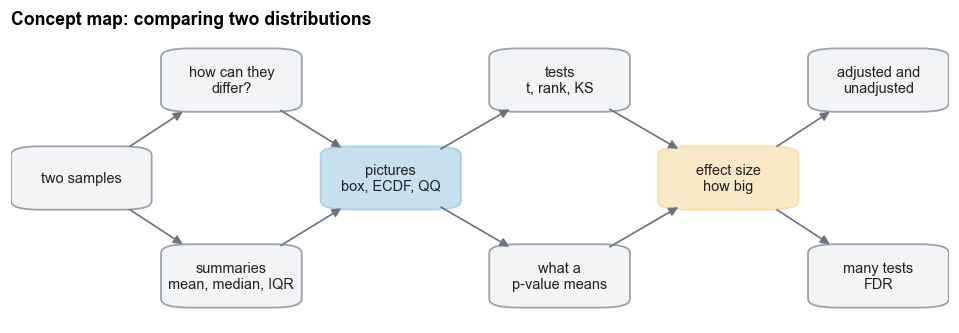

In [2]:
fig = draw_concept_map(); plt.show()

## 먼저 알아 둘 것: 용어와 기호

| 낱말·기호 | 쉬운 말 | 이 노트북에서 |
|---|---|---|
| t 분포, 자유도 ν | 정규와 비슷한 종 모양인데 꼬리가 더 두꺼운 분포. 자유도(degrees of freedom)라는 손잡이가 작을수록 꼬리가 두껍고, 클수록 정규에 가까워집니다(아래 셀에서 계산으로 확인) | 1 절 D 의 "꼬리가 두꺼운 분포", 5 절 t 검정 |
| t 검정의 p 값 | t 값을 계산한 뒤, 자유도 ν 인 t 분포에서 그 값보다 바깥에 있을 확률을 잽니다. Welch t 의 ν 는 두 군의 분산으로 계산합니다(Welch-Satterthwaite 식, 5 절) | 5 절 |
| 95% 신뢰구간(CI) | 같은 방법으로 데이터를 모으고 구간을 만드는 일을 여러 번 되풀이하면, 그중 약 95% 의 구간이 참값을 포함하도록 만든 범위(아래 셀에서 시뮬레이션으로 확인) | 7 절 |
| 역분산 가중 평균 | 여러 추정값을 평균할 때 덜 흔들리는(표준오차가 작은) 값에 더 큰 무게 $1/SE^2$ 를 주는 평균 | 7 절의 보정 값 |
| $s_p$ (합동 표준편차) | 두 군 **안의** 분산을 자유도 $(n_i - 1)$ 로 가중 평균한 값의 제곱근. 두 군 데이터를 그냥 합쳐 낸 SD 가 아닙니다 | 6 절 Cohen's d |
| nat | 자연로그(밑 e)로 잰 정보량의 단위 | 9 절 KL 발산 |

In [3]:
g = np.linspace(-6, 6, 1201)
gap = {nu: np.abs(stats.t.pdf(g, nu) - stats.norm.pdf(g)).max() for nu in (3, 30, 300)}
print("t 분포와 정규 밀도의 최대 차이:", {k: round(v, 4) for k, v in gap.items()})
assert gap[3] > gap[30] > gap[300]
rng_ci = np.random.default_rng(50); hits = 0
for _ in range(4000):                       # 95% 신뢰구간이 참값(0)을 포함하는 비율
    d = rng_ci.normal(0, 1, 30); se = d.std(ddof=1) / np.sqrt(30); tq = stats.t.ppf(0.975, 29)
    hits += (d.mean() - tq * se) < 0 < (d.mean() + tq * se)
print("95% 신뢰구간이 참값을 포함한 비율:", hits / 4000)
assert abs(hits / 4000 - 0.95) < 0.015

t 분포와 정규 밀도의 최대 차이: {3: 0.0407, 30: 0.0045, 300: 0.0005}


95% 신뢰구간이 참값을 포함한 비율: 0.9535


## 1. "다르다"에는 네 가지가 있다

**한 줄 정의**: 두 분포는 중심(위치), 퍼짐, 모양, 꼬리 중 어느 것이든 다를 수 있고, 각 차이를 잡는 그림·검정이 다릅니다.

**왜 필요한가**: "평균이 같으니 같은 분포"는 틀린 결론일 수 있습니다. 아래 C, D 는 평균이 같고 D 는 SD 까지 같지만, 분명히 다른 분포입니다.

**숫자로 따라가기**
- A: 평균 0 대 1 (SD 는 둘 다 1)
- B: 평균 둘 다 0, SD 1 대 1.8
- C: 평균·중앙값 둘 다 0, 하나는 봉우리 하나, 하나는 봉우리 둘
- D: 평균 0, SD 1 로 같고, 꼬리 무게만 다름(t 분포, 자유도 3, SD 를 1 로 맞춤)

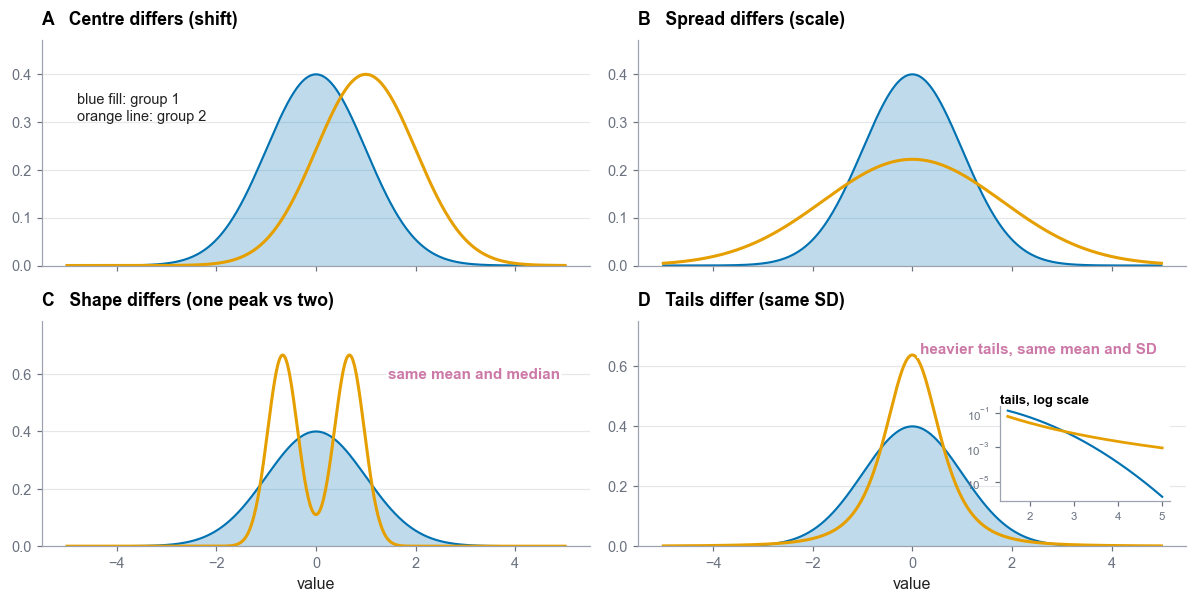

In [4]:
fig = draw_four_differences(); plt.show()

**그림에서 볼 것**
- 파란 면이 군 1, 주황 선이 군 2 입니다.
- A 는 통째로 옆으로 밀렸고, B 는 넓게 퍼졌고, C 는 가운데가 비었고, D 는 가운데가 더 뾰족합니다.
- D 의 양 끝은 보통 눈금으로는 둘 다 0 처럼 보입니다. 오른쪽 작은 그림(세로축 로그)에서 x 가 커질수록 주황이 파랑보다 점점 더 위에 있는 것이 "꼬리가 두껍다"는 뜻입니다.

## 2. 요약값: 평균은 끌려가고 중앙값은 버틴다

**한 줄 정의**: 평균과 SD 는 모든 값을 쓰기 때문에 튀는 값 하나에 크게 흔들리고, 중앙값·IQR(사분위 범위)·MAD(중앙값 절대 편차)는 가운데 값들만 써서 튀는 값에 강합니다(robust). 아래 계산으로 직접 확인합니다.

**왜 필요한가**: 깊이나 VAF 에는 반복 서열, 증폭 구간 같은 튀는 값이 흔합니다. 평균만 보면 한두 창 때문에 결론이 바뀝니다.

**숫자로 따라가기**: 창 10 개의 깊이 28~38 에 120x 창 하나를 더하면, 평균은 32.8 → 40.7 로 8 가까이 뛰지만 중앙값은 32.5 → 33 으로 거의 그대로입니다.

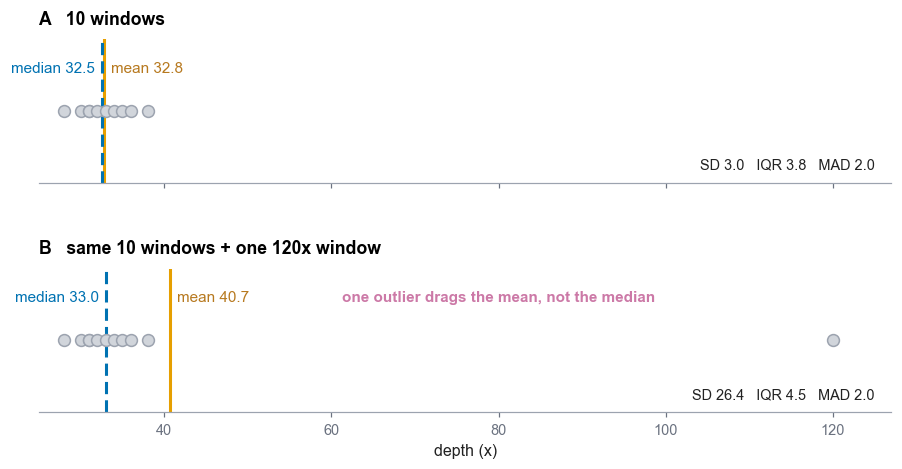

In [5]:
fig, (m0, m1, md0, md1) = draw_robust(); plt.show()
assert round(m0, 1) == 32.8 and round(m1, 1) == 40.7 and md0 == 32.5 and md1 == 33

**그림에서 볼 것**
- 주황 실선이 평균, 파란 점선이 중앙값입니다. B 에서 120 짜리 점 하나가 평균을 오른쪽으로 끌고 갔습니다.
- 오른쪽 아래 숫자: SD 는 3.0 → 26.4 로 아홉 배 가까이 커지지만, IQR 은 3.8 → 4.5, MAD 는 2.0 그대로입니다.

## 3. 그림으로 비교하기: 같은 데이터, 네 가지 그림

**한 줄 정의**: 상자 그림은 중앙값과 사분위만, 히스토그램은 모양을, ECDF(경험적 누적 분포)는 모든 값을 한 번에, QQ 그림은 두 분포의 분위수를 맞대어 보여 줍니다.

**왜 필요한가**: 그림마다 숨기는 것이 다릅니다. 아래 두 군은 중앙값과 IQR 이 거의 같아서 상자만 보면 같아 보이지만, 군 2 는 봉우리가 둘입니다.

**숫자로 따라가기**: 군 1 은 표준정규, 군 2 는 ±0.67 에 봉우리가 있는 쌍봉 분포입니다(각 봉우리 SD 0.3). 둘 다 중앙값 0, IQR 약 1.35 입니다.

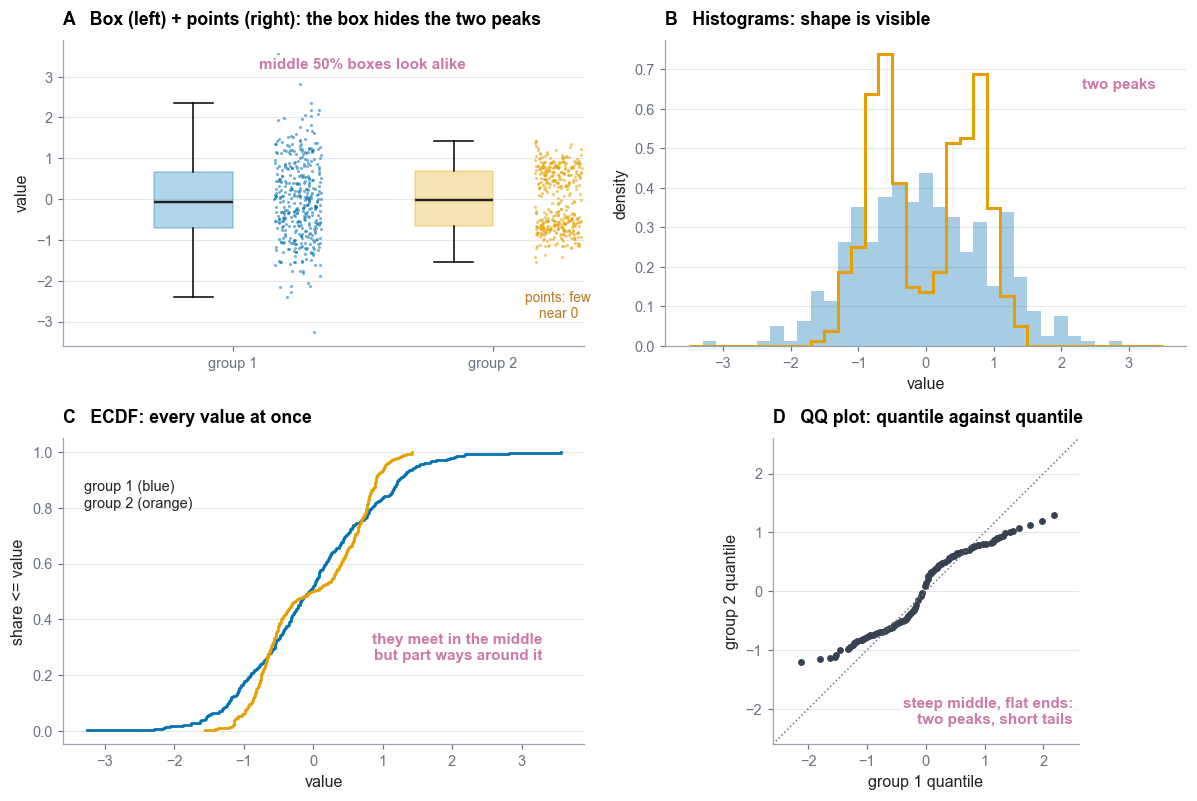

중앙값: -0.06 -0.03   IQR: 1.37 1.36


In [6]:
fig, a1, a2 = draw_four_pictures(); plt.show()
iqr = lambda d: np.subtract(*np.percentile(d, [75, 25]))
print("중앙값:", round(np.median(a1), 2), round(np.median(a2), 2), "  IQR:", round(iqr(a1), 2), round(iqr(a2), 2))
assert abs(iqr(a1) - iqr(a2)) < 0.25 and abs(np.median(a1) - np.median(a2)) < 0.25

**그림에서 볼 것**
- A: 두 상자(왼쪽)는 거의 같습니다. 상자 오른쪽에 뿌린 점을 보면 군 2(주황)는 0 근처에 점이 드물고 위아래 두 곳에 몰려 있습니다. **상자만 그리지 말고 점을 같이 그리는 이유**입니다.
- B: 히스토그램에서는 주황 선이 봉우리 둘입니다.
- C: ECDF 두 곡선이 가운데(중앙값 근처)에서 만나고, 그 양옆에서는 주황이 더 가파르게 오르며 엇갈립니다. 가운데는 같고 모양이 다르다는 표시입니다.
- D: QQ 점들이 가운데(군 1 분위수 −0.5~0.5)에서는 점선(y = x)보다 가파르게 오르고, 양 끝에서는 점선보다 눕습니다.
  군 2 는 가운데가 비어 값이 두 봉우리로 갈라지고(가운데가 가파름), 꼬리는 정규보다 짧기 때문입니다(양 끝이 누움).

> **시퀀싱 데이터에서는**: 배치 사이 깊이 분포나 VAF 분포를 비교할 때 ECDF 나 QQ 를 먼저 그리면, 평균 차이인지(평행 이동) 퍼짐 차이인지(기울기) 꼬리 차이인지가 한 장에 보입니다.
> 다만 **검정은 시료 단위로** 합니다. 한 시료 안의 창이나 변이들은 같은 라이브러리·이웃 자리를 공유해 서로 독립이 아닌데, 5 절의 검정들은 모두 관측값이 독립이라고 가정합니다 [3]. 창 수만큼 n 을 키우면 p 값이 지나치게 작아집니다. 시료마다 요약값(예: 중앙값 깊이)을 하나 만들어 시료끼리 비교하세요.

### ECDF 와 KS 통계량

**한 줄 정의**: ECDF $\hat F(x)$ 는 "값이 x 이하인 점의 비율"을 그린 계단이고, KS(Kolmogorov-Smirnov) 통계량 D 는 두 ECDF 사이 세로 간격의 최댓값입니다 [3].

**수식 풀어 읽기**

| 기호 | 소리 내어 읽기 | 뜻 | 그림에서 어디 |
|---|---|---|---|
| $\mathbf{1}[x_i \le x]$ | "x_i 가 x 이하면 1, 아니면 0" | 점 하나를 세는 스위치 | – |
| $\frac{1}{n}\sum_i \mathbf{1}[\cdot]$ | "그 1 들을 더해 n 으로 나눔" | x 이하인 점의 비율 | 계단의 높이 |
| $\max_x \lvert \hat F_1 - \hat F_2 \rvert$ | "x 를 움직이며 두 계단 차이의 최댓값" | KS 통계량 D | 자주색 화살표 |

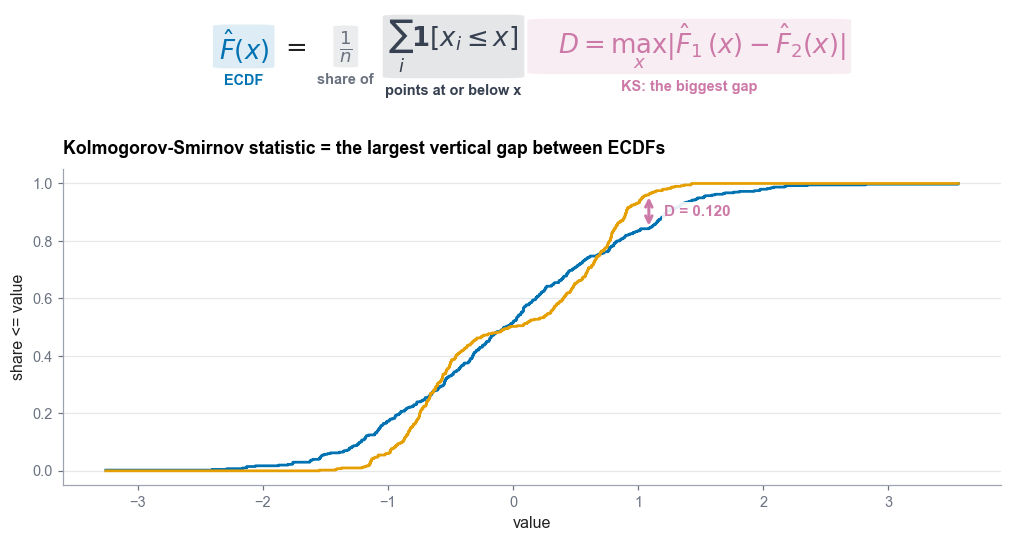

직접 계산한 D = 0.12   scipy ks_2samp = 0.12   p = 0.0063


In [7]:
fig, D = draw_ecdf_ks(a1, a2); plt.show()
assert abs(D - stats.ks_2samp(a1, a2).statistic) < 1e-12
print("직접 계산한 D =", round(D, 4), "  scipy ks_2samp =", round(stats.ks_2samp(a1, a2).statistic, 4), "  p =", f"{stats.ks_2samp(a1, a2).pvalue:.2g}")

**그림에서 볼 것**: 두 계단 사이가 가장 많이 벌어진 곳(자주색 화살표)의 길이가 D 입니다. 손으로 계산한 D 가 SciPy `ks_2samp` 의 통계량과 같습니다.

### QQ 그림 읽는 법

**한 줄 정의**: QQ 그림은 군 1 의 분위수(가로)와 군 2 의 같은 분위수(세로)를 점으로 찍은 것이라, 두 분포가 같으면 점이 y = x 선 위에 놓입니다.

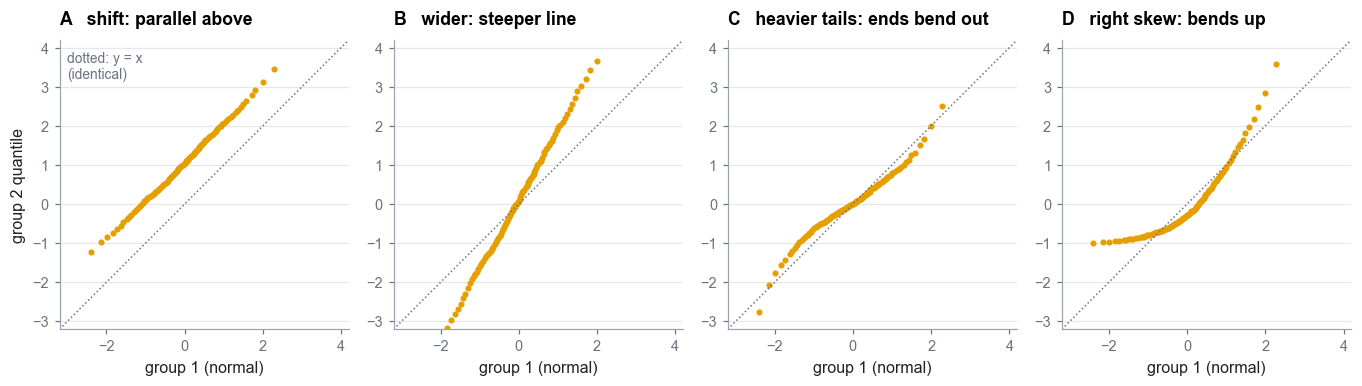

In [8]:
fig = draw_qq_patterns(); plt.show()

**그림에서 볼 것**
- A: 선과 나란히 위로(평행 이동) = 중심 차이. B: 선보다 가파르게 = 퍼짐 차이.
- C: 가운데는 선보다 눕고, 양 끝이 선보다 바깥(위·아래)으로 휨 = 꼬리가 정규보다 길다(두껍다). 3 절 D 의 쌍봉 분포(가운데가 가파르고 끝이 누움)와는 **반대 방향**의 휨입니다.
- D: 한쪽 끝만 위로 휨 = 치우침(skew).

## 4. p 값은 무엇을 재나: 순열로 직접 만들어 보기

**한 줄 정의**: p 값은 "귀무가설(검정마다 다름)과 그 검정의 가정이 맞다면, 검정 통계량이 지금 본 값만큼 또는 그보다 극단적으로(양측 검정이면 절댓값으로) 나올 확률"입니다 [11].
귀무가설은 검정마다 다릅니다. 순열 검정은 "두 군이 같은 분포에서 무작위로 뽑혔다", Welch t 검정은 "두 군의 평균이 같다" 입니다 [3]. 이 절에서는 순열 검정으로 귀무 분포를 직접 만들어 봅니다.

**왜 필요한가**: p 값은 "차이가 클 확률"도, "귀무가설이 맞을 확률"도, "데이터가 우연만으로 만들어졌을 확률"도 아닙니다(ASA 성명 원칙 2) [11]. 가정이 틀리면 작은 p 는 귀무가설이 아니라 가정이 틀렸다는 신호일 수도 있습니다(원칙 1) [11]. 이 정의를 몸으로 익히려면 귀무가설 아래의 세계를 직접 만들어 보면 됩니다.

**숫자로 따라가기**: 귀무가설이 맞다면 군 이름표는 아무 뜻이 없으니, 이름표를 무작위로 섞어도 됩니다.
섞을 때마다 평균 차이를 계산하면 "차이가 없을 때 나오는 차이들의 분포"(귀무 분포)가 생깁니다. 그중 관측값보다 극단적인 비율이 p 값입니다.
SciPy 의 `permutation_test` 문서도 독립 표본에 대해 귀무가설을 "같은 분포에서 무작위로 뽑혔다"로 적습니다 [3].

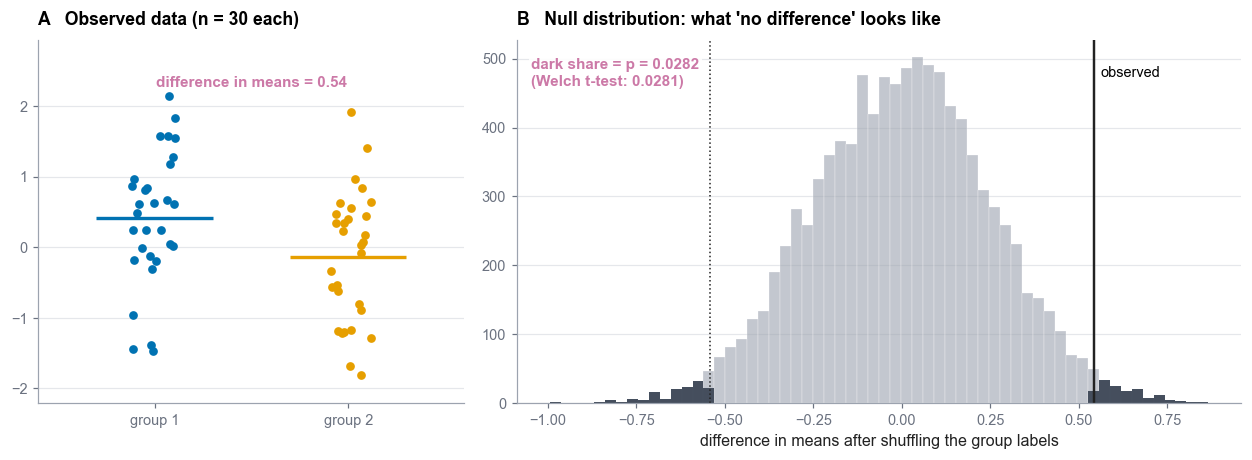

In [9]:
fig, p_perm, p_welch = draw_permutation(); plt.show()
assert p_perm < 0.05 and abs(np.log10(p_perm) - np.log10(p_welch)) < 0.5

**그림에서 볼 것**
- A: 실제 관측한 두 군과 평균(가로선)입니다. 차이가 0.54 입니다(진짜 차이는 0.6 으로 만들었습니다).
- B: 이름표를 1 만 번 섞어 만든 귀무 분포입니다. 검은 선(관측값)과 점선(반대쪽)보다 바깥인 진회색 부분의 비율이 p 값입니다. Welch t 검정이 주는 p 와 거의 같습니다.

**직접 바꿔 보기**: `draw_permutation(shift=0)` 으로 진짜 차이를 없애 보세요. 관측값이 귀무 분포 가운데에 놓이고 p 가 커집니다.

## 5. 검정마다 보는 것이 다르다

**한 줄 정의**
- **Welch t 검정**: 두 군의 **평균**이 같은지 봅니다. 두 군의 분산이 같다고 가정하지 않습니다 [3, 4].
- **Mann-Whitney U(Wilcoxon 순위합) 검정**: 한 군이 다른 군보다 **체계적으로 큰 쪽(확률적으로 큼)**인지 순위로 봅니다 [3, 5].
- **KS 검정**: 두 **분포 전체(ECDF)**가 같은지 봅니다. 모양 차이에도 반응합니다 [3].
- **순열 검정**: 고른 통계량(여기서는 평균 차이)에 대해, 이름표를 섞어 귀무 분포를 직접 만듭니다 [3].

**수식 풀어 읽기** (Welch t)

$$t = \frac{\bar x_1 - \bar x_2}{\sqrt{s_1^2/n_1 + s_2^2/n_2}}$$

| 기호 | 소리 내어 읽기 | 뜻 |
|---|---|---|
| $\bar x_1 - \bar x_2$ | "평균 차이" | 신호 |
| $s_i^2 / n_i$ | "분산 나누기 표본 수" | 군 i 평균의 불확실성(제곱) |
| $\sqrt{\cdot + \cdot}$ | "둘을 더한 것의 제곱근" | 평균 차이의 표준오차(잡음). 두 군의 분산을 따로 씀 |

이 식으로 손 계산한 t 가 SciPy `ttest_ind(equal_var=False)` 와 같은지, 그리고 Welch-Satterthwaite 자유도 $\nu = \frac{(s_1^2/n_1 + s_2^2/n_2)^2}{(s_1^2/n_1)^2/(n_1-1) + (s_2^2/n_2)^2/(n_2-1)}$ 로 t 분포에서 구한 p 가 SciPy 의 p 와 같은지 아래에서 확인합니다.

**검정마다 반응하는 것과 가정**

| 검정 | 무엇에 반응하나 | 꼭 필요한 가정 |
|---|---|---|
| Welch t | 평균 차이 | 두 표본이 독립이고 표본 안 관측값도 서로 독립 [3]. 평균 차이를 t 분포로 근사하므로, 표본이 작고 분포가 많이 치우치면 p 가 부정확해집니다(P3 의 중심극한정리 조건) |
| Mann-Whitney U | 한쪽 값이 다른 쪽보다 클 확률 $P(X > Y)$ 가 1/2 에서 벗어났는가 | 독립 표본 [3]. 그래서 퍼짐만 다르고 $P(X>Y) = 1/2$ 이면 거의 못 잡습니다(아래 그림 셋째 열) |
| KS | ECDF 전체의 최대 차이 | 독립 표본, **연속 분포**에서 뽑혔다는 가정 [3]. 정수인 깊이·alt read 수처럼 같은 값(동점)이 많으면 이 가정이 깨집니다(아래 셀) |
| 순열 | 고른 통계량(여기서는 평균 차이) | 귀무가설 아래에서 군 이름표를 바꿔도 같은 분포라는 것(교환 가능성)과 관측 단위의 독립 [3] |

Mann-Whitney 처럼 "$P(X>Y) = 1/2$ 인가"를 묻되 두 군의 퍼짐이 같다는 가정 없이 하려면 Brunner-Munzel 검정을 쓸 수 있습니다. SciPy `brunnermunzel` 문서는 이 검정이 "Unlike the Wilcoxon-Mann-Whitney's U test, ... does not require the assumption of equivariance of two groups" 라고 적습니다 [3].

In [10]:
xx, yy = np.random.default_rng(48).normal(0.5, 1, 25), np.random.default_rng(49).normal(0, 2, 40)
res = stats.ttest_ind(xx, yy, equal_var=False)
vx, vy = xx.var(ddof=1) / len(xx), yy.var(ddof=1) / len(yy)
nu = (vx + vy) ** 2 / (vx ** 2 / (len(xx) - 1) + vy ** 2 / (len(yy) - 1))
p_hand = 2 * stats.t.sf(abs(welch_t(xx, yy)), nu)
assert abs(welch_t(xx, yy) - res.statistic) < 1e-10 and abs(nu - res.df) < 1e-8 and abs(p_hand - res.pvalue) < 1e-12
print("손 계산 t =", round(welch_t(xx, yy), 4), " 자유도 =", round(nu, 2), " p =", round(p_hand, 4), "   scipy:", round(res.statistic, 4), round(res.df, 2), round(res.pvalue, 4))

# 정수 데이터(같은 값이 많음)에서 KS: 같은 분포끼리 비교해도 p < 0.05 가 얼마나 자주 나오나 (이 노트북의 시뮬레이션)
rng_ks = np.random.default_rng(51)
ks_false = np.mean([stats.ks_2samp(rng_ks.poisson(30, 100), rng_ks.poisson(30, 100)).pvalue < 0.05 for _ in range(1000)])
print("정수 깊이(포아송 30)끼리 KS 를 했을 때 p < 0.05 비율:", ks_false, "(연속 분포라면 약 0.05)")
assert ks_false < 0.04

손 계산 t = 0.0818  자유도 = 55.28  p = 0.9351    scipy: 0.0818 55.28 0.9351
정수 깊이(포아송 30)끼리 KS 를 했을 때 p < 0.05 비율: 0.019 (연속 분포라면 약 0.05)


이제 네 검정을 네 가지 상황에 300 번씩 돌려, 각각 "p < 0.05" 라고 몇 번 말하는지 셉니다(검정력, power).

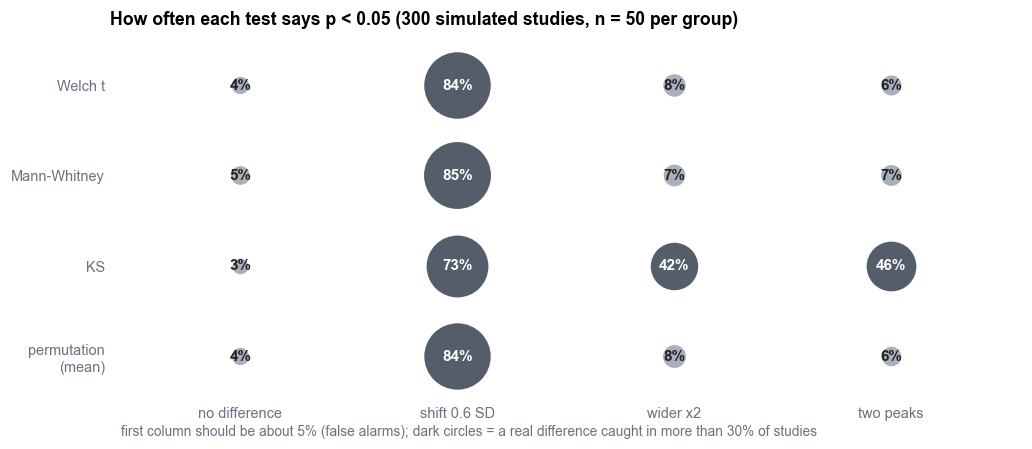

In [11]:
fig, R = draw_power(); plt.show()
assert np.all(np.abs(R[:, 0] - 0.05) < 0.05)
assert R[2, 3] > R[0, 3] + 0.3 and R[2, 2] > R[0, 2] + 0.3

**그림에서 볼 것** (이 노트북의 시뮬레이션 결과)
- 첫째 열(진짜 차이 없음): 네 검정 모두 5% 근처입니다. 기준 0.05 는 "차이가 없을 때 잘못 외치는 비율"이기 때문입니다.
- 둘째 열(평균 이동): 네 검정 모두 잘 잡습니다.
- 셋째 열(퍼짐만 다름): 평균을 보는 t·순열 검정과, $P(X>Y)$ 를 보는 Mann-Whitney 는 5% 근처라 거의 못 잡습니다(퍼짐만 달라서는 $P(X>Y)$ 가 1/2 그대로). 분포 전체를 보는 KS 만 40% 대로 어느 정도 잡습니다.
- 넷째 열(봉우리 둘, 평균·분산은 같게 맞춤): 역시 KS 만 40% 대로 잡습니다. 군마다 50 개로는 KS 도 절반을 놓칩니다.
- 그래서 "검정에서 차이가 없었다"는 "그 검정이 보는 종류의 차이가 없었다"일 뿐입니다.

## 6. p 값과 효과 크기는 다른 질문이다

**한 줄 정의**: p 값은 "차이가 없다면 이만한 차이가 얼마나 자주 나오나"를, 효과 크기는 "차이가 얼마나 큰가"를 답합니다. ASA 성명은 p 값이 효과의 크기나 결과의 중요성을 재지 않는다고 적습니다(원칙 5) [11]. 표본이 크면 아주 작은 차이도 p 가 아주 작아집니다.

**왜 필요한가**: 코호트가 수백~수천 명이면 의미 없을 만큼 작은 차이도 "유의"하게 나옵니다. 크기를 같이 적지 않으면 작은 차이를 큰 발견처럼 읽게 됩니다.

**효과 크기 세 가지**
- **표준화 평균 차이**(흔히 Cohen's d 라고 부름 [6]): $(\bar x_1 - \bar x_2)/s_p$, 평균 차이를 SD 단위로. 이 노트북은 합동 표준편차 $s_p = \sqrt{\frac{(n_1-1)s_1^2 + (n_2-1)s_2^2}{n_1+n_2-2}}$ (두 군 **안의** 분산의 가중 평균, 두 군 데이터를 합쳐 낸 SD 가 아님)로 나눕니다.
- **중앙값 차이**: 튀는 값에 강한 크기.
- **AUC = P(X > Y)**: 군 1 에서 하나, 군 2 에서 하나 뽑았을 때 군 1 쪽이 클 확률. 0.5 면 차이 없음. Mann-Whitney U 통계량을 $n_1 n_2$ 로 나눈 값과 같습니다(ROC 곡선 아래 넓이가 Wilcoxon 통계량이 추정하는 확률과 같다는 Hanley & McNeil 의 결과) [8].
  같은 값(동점)이 있으면 $U/(n_1 n_2) = P(X > Y) + \tfrac{1}{2}P(X = Y)$ 입니다. 깊이처럼 정수인 데이터에서는 동점이 많으므로 이 꼴로 읽어야 합니다(아래 셀에서 직접 세어 확인).

**숫자로 따라가기**: d = 0.05 는 평균이 SD 의 5% 만큼 다르다는 뜻이고, AUC 로는 약 0.514 입니다.

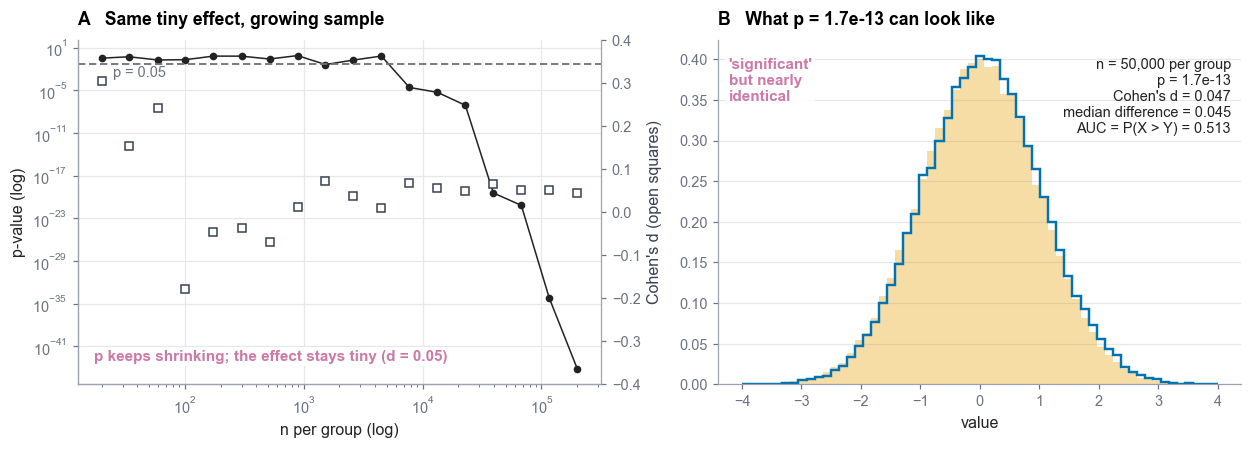

U/(n1 n2) = 0.437   P(X>Y) + 0.5 P(X=Y) = 0.437   (동점 비율 0.052 )


In [12]:
fig, auc, dd = draw_p_vs_effect(); plt.show()
assert abs(auc - stats.norm.cdf(0.05 / np.sqrt(2))) < 0.01 and abs(dd - 0.05) < 0.02

# 정수 데이터(동점 많음)에서 U/(n1 n2) = P(X > Y) + 0.5 P(X = Y) 인지 짝을 모두 세어 확인
xi, yi = np.random.default_rng(52).poisson(30, 300), np.random.default_rng(53).poisson(31, 300)
U = stats.mannwhitneyu(xi, yi).statistic
gt, eq = (xi[:, None] > yi[None, :]).mean(), (xi[:, None] == yi[None, :]).mean()
print("U/(n1 n2) =", round(U / (300 * 300), 4), "  P(X>Y) + 0.5 P(X=Y) =", round(gt + 0.5 * eq, 4), "  (동점 비율", round(eq, 3), ")")
assert abs(U / (300 * 300) - (gt + 0.5 * eq)) < 1e-12

**그림에서 볼 것**
- A: 같은 작은 효과(d = 0.05)를 표본 수만 늘려 가며 검정했습니다. p 값(검은 선)은 n 이 커질수록 0.05 선(회색 점선)을 뚫고 끝없이 내려갑니다.
  속이 빈 회색 네모(측정한 d, 오른쪽 축)는 표본이 작을 때 크게 출렁이다가, 표본이 커지면 0.05 근처로 모입니다. 크기는 커지지 않습니다.
- B: 군마다 5 만 명이면 p 가 1.7e-13 인데, 두 히스토그램(파랑 선 = 군 1, 주황 면 = 군 2)은 거의 겹칩니다. 효과 크기 숫자(d 0.05, AUC 0.51)가 이 겹침을 말해 줍니다.

## 7. 보정 전과 보정 후를 나란히

**한 줄 정의**: 군 사이 차이가 사실은 다른 변수(배치, 아형, 나이 등)의 구성 차이에서 올 수 있으므로, 그 변수를 고려하지 않은 값(보정 전)과 고려한 값(보정 후)을 **둘 다** 적습니다.

**왜 필요한가**: 보정 전 값만 보면 배치 효과를 군 효과로 오해하고, 보정 후 값만 보면 원래 데이터에서 무엇이 보였는지 알 수 없습니다. 두 값이 다르면 그 차이 자체가 정보입니다.

**숫자로 따라가기** (이 노트북의 시뮬레이션, 일부러 만든 상황)
- 배치 2 는 깊이가 6 높게 나오고, 군 자체의 효과는 0 입니다.
- 군 A 는 80% 가 배치 2, 군 B 는 20% 만 배치 2 입니다.
- 그러면 보정 전 차이는 약 0.6 × 6 = 3.6 이 나오고, 배치 안에서 비교하면 0 근처입니다.

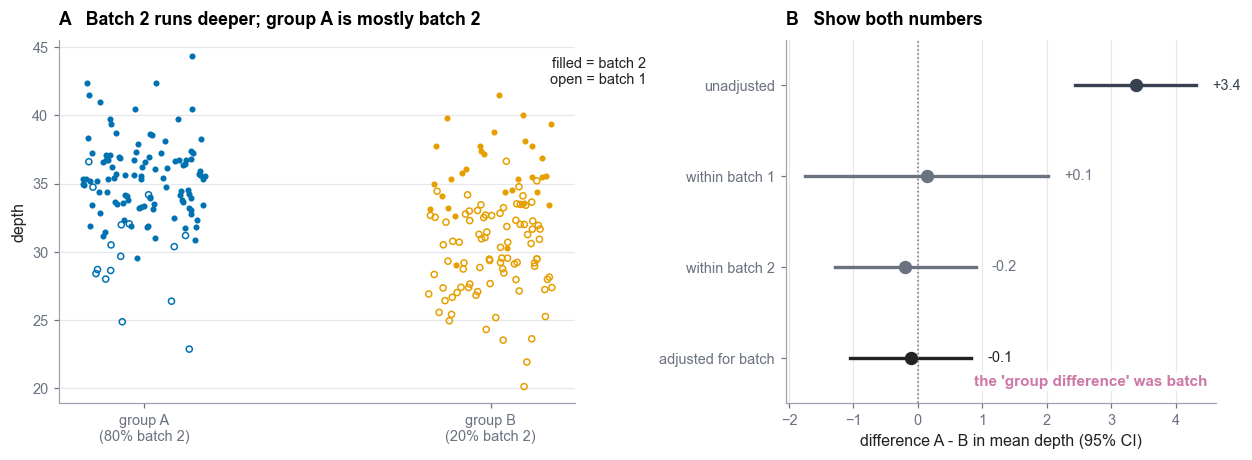

In [13]:
fig, unadj, adj = draw_confounding(); plt.show()
assert unadj > 2.5 and adj[1] < 0 < adj[2]

**그림에서 볼 것**
- A: 꽉 찬 점(배치 2)이 위쪽에 몰려 있고, 군 A(파랑)에 꽉 찬 점이 많습니다.
- B: 보정 전(진회색)은 +3 정도로 0 에서 멀지만, 배치 1 안, 배치 2 안, 그리고 두 배치 값을 역분산 가중 평균한 보정 값(검정)은 95% 신뢰구간이 0 을 지납니다.

> **시퀀싱 데이터에서는**: 나이군·아형·배치가 서로 겹치는 코호트에서는 이런 일이 실제로 생깁니다. 비교할 때마다 보정 전과 보정 후 값을 나란히 적어 두면 해석이 흔들리지 않습니다.

## 8. 검정을 많이 하면: 다중 검정과 FDR

**한 줄 정의**: 검정을 m 번 하면 진짜 차이가 하나도 없어도 약 $0.05m$ 개가 우연히 p < 0.05 가 됩니다. Benjamini-Hochberg(BH) 방법은 "유의하다고 한 것 중 틀린 것의 기대 비율"(FDR, false discovery rate)을 q 이하로 맞춥니다 [3, 7].
정확히는 검정들이 서로 독립이거나 "양의 회귀 의존(positive regression dependency)" 관계일 때, BH 로 자르면 FDR 이 $q\,m_0/m$ 이하($m_0$ = 진짜 차이가 없는 검정 수)가 됩니다.
유전자나 창처럼 서로 얽힌 검정이라 이 조건이 걱정되면, 더 보수적이지만 의존이 있어도 보장되는 Benjamini-Yekutieli(BY, `method="by"`)를 쓸 수 있습니다 [3].

**숫자로 따라가기**: 유전자 1,000 개 중 100 개에만 진짜 차이가 있다고 합니다. p < 0.05 로 자르면 차이 없는 900 개 중 약 45 개가 우연히 걸립니다.

**수식 풀어 읽기** (BH 의 규칙)

p 값을 작은 것부터 $p_{(1)} \le p_{(2)} \le \dots \le p_{(m)}$ 로 줄 세우고, $p_{(i)} \le \frac{i}{m} q$ 를 만족하는 가장 큰 i 까지를 유의하다고 합니다.

| 기호 | 소리 내어 읽기 | 뜻 | 그림에서 어디 |
|---|---|---|---|
| $p_{(i)}$ | "i 번째로 작은 p" | 줄 세운 p 값 | B 의 점 |
| $\frac{i}{m} q$ | "i 나누기 m 곱하기 q" | 순위마다 다른 문턱 | B 의 검은 선 |

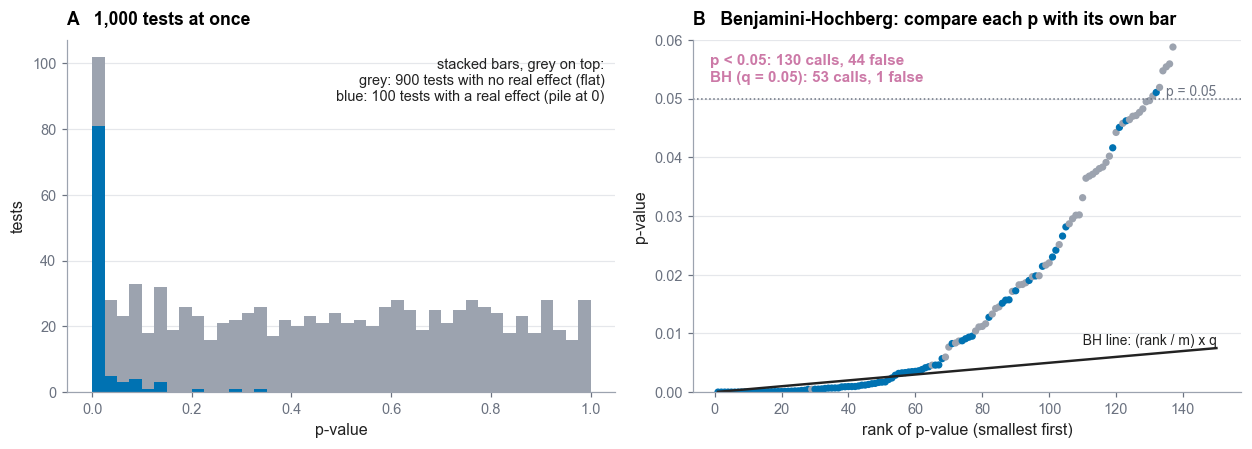

직접 BH: 53 개 유의  scipy BH: 53 개  scipy BY(더 보수적): 21 개


In [14]:
fig, p, padj, truth = draw_bh(); plt.show()
order = np.argsort(p); ps = p[order]; m = len(p)
below = np.nonzero(ps <= np.arange(1, m + 1) / m * 0.05)[0]
k_bh = below.max() + 1 if len(below) else 0
assert k_bh == (padj < 0.05).sum()
n_by = (stats.false_discovery_control(p, method="by") < 0.05).sum()
print("직접 BH:", k_bh, "개 유의  scipy BH:", (padj < 0.05).sum(), "개  scipy BY(더 보수적):", n_by, "개")
assert n_by <= k_bh

**그림에서 볼 것**
- A: 막대는 두 종류를 쌓은 것입니다(파랑 아래, 회색 위). 진짜 차이가 없는 900 개(회색)의 p 는 0~1 에 평평하게 퍼지고, 진짜 차이가 있는 100 개(파랑)는 0 근처에 쌓입니다.
- B: 작은 p 부터 줄 세운 점과 BH 선(검은 선). 선 아래에 있는 마지막 점까지가 BH 가 고른 것입니다. 자주색 글씨에 두 방법의 결과(유의 개수와 그중 틀린 개수)가 있습니다.
- 손으로 구현한 BH 와 SciPy `false_discovery_control(method="bh")` 가 같은 개수를 고릅니다.

## 9. 다음으로 이어지는 다리: KL 발산

**한 줄 정의**: KL(Kullback-Leibler) 발산 $D_{KL}(P \| Q) = \sum_k P(k) \log \frac{P(k)}{Q(k)}$ 는 "P 가 진짜일 때 Q 로 설명하면 얼마나 손해인가"를 재는 거리 비슷한 양입니다. 두 분포가 같으면 0 이고, 순서를 바꾸면 값이 달라집니다 [3, 9]. SciPy `entropy` 의 기본 로그 밑은 e(자연로그)이므로 단위는 nat 입니다 [3].

**왜 필요한가**: P5 의 최대우도는 "데이터 분포와 모델 분포의 KL 을 줄이는 것"으로 읽을 수 있고, 베이지안 계산의 근사 방법들에서도 계속 나옵니다. 지금은 모양만 익혀 둡니다.

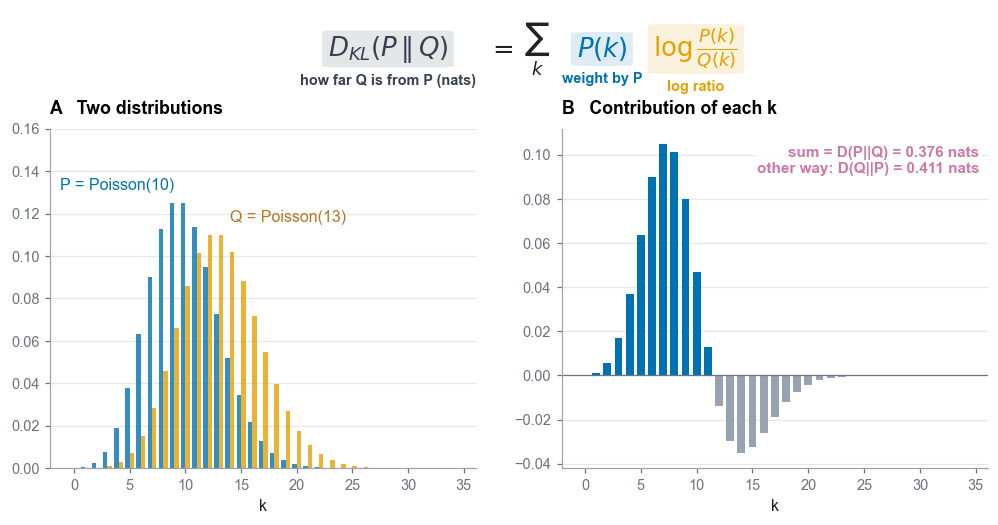

In [15]:
fig, D1, D2 = draw_kl(); plt.show()
k = np.arange(0, 200)
assert abs(D1 - np.sum(stats.poisson.pmf(k, 10) * np.log(stats.poisson.pmf(k, 10) / stats.poisson.pmf(k, 13)))) < 1e-3
assert D1 > 0 and D2 > 0 and abs(D1 - D2) > 0.01

**그림에서 볼 것**
- A: P = 포아송(10)(파랑), Q = 포아송(13)(주황).
- B: k 마다 $P(k)\log(P(k)/Q(k))$ 를 막대로 그렸습니다. P 가 Q 보다 큰 왼쪽(k ≤ 11, 파랑)은 양수, P 가 Q 보다 작은 오른쪽(회색)은 음수입니다.
  막대를 모두 더한 값이 D(P‖Q) = 0.376 nat 이고, 양수 쪽이 늘 더 커서 합은 0 이상입니다. 순서를 바꾼 D(Q‖P) = 0.411 은 다른 값입니다.

## 연습 문제

1. 깊이 분포가 두 배치에서 "평균은 같고 퍼짐만 다르다"면, Welch t 검정과 KS 검정 중 어느 것이 차이를 잡을까요?
2. 군마다 1 만 명, 평균 차이가 SD 의 2%(d = 0.02)일 때 AUC 는 대략 얼마인가요? (정규 분포라고 할 때 AUC = Φ(d/√2))
3. 검정 2 만 번을 하고 진짜 차이가 하나도 없으면, p < 0.01 인 것은 대략 몇 개 나오나요?
4. 7 절에서 군 A 의 배치 2 비율이 군 B 와 같았다면 보정 전 차이는 대략 얼마였을까요?

<details><summary>정답 보기</summary>

1. KS. t 검정은 평균만 보므로 퍼짐 차이에는 거의 반응하지 않습니다(5 절 그림 셋째 열). 단, 비교 단위는 창이 아니라 **시료**여야 하고(시료마다 요약값 하나), 깊이가 정수라 KS 의 p 는 보수적일 수 있습니다(5 절).
2. $\Phi(0.02/1.414) = 0.506$. 거의 반반입니다.
3. 약 $20{,}000 \times 0.01 = 200$ 개.
4. 0 근처. 배치 구성이 같으면 배치 효과가 두 군에 똑같이 들어가 차이에서 지워집니다.

</details>

In [16]:
assert abs(stats.norm.cdf(0.02 / np.sqrt(2)) - 0.506) < 1e-3

## 정리

- 분포는 중심·퍼짐·모양·꼬리 어느 것으로든 다를 수 있습니다. 평균만 비교하면 나머지를 놓칩니다.
- 요약값은 튀는 값에 약한 것(평균, SD)과 강한 것(중앙값, IQR, MAD)이 있습니다.
- 그림: 상자 그림은 점과 같이, 모양은 히스토그램, 전체는 ECDF, 분위수 비교는 QQ.
- p 값 = 귀무가설과 가정이 맞을 때, 지금 이상으로 극단적인 통계량이 나올 확률. 귀무가설은 검정마다 다르고, 이름표를 섞어 직접 만들 수도 있습니다. 데이터가 우연으로 생겼을 확률도, 효과의 크기도 아닙니다.
- 검정마다 보는 차이와 가정이 다릅니다(평균: t, $P(X>Y)$: Mann-Whitney, 분포 전체: KS). 모두 관측값의 독립을 가정하므로 비교 단위는 시료입니다.
- p 값과 효과 크기는 다른 질문입니다. 큰 코호트일수록 크기를 같이 적습니다.
- 보정 전과 보정 후 값을 나란히 적습니다.
- 검정이 많으면 FDR(BH)로 조절합니다. 검정끼리 강하게 얽혀 있으면 BY 를 씁니다.
- KL 발산은 두 분포의 차이를 재는 양이고, P5 이후에 다시 나옵니다.

## 출처

1. Diez DM, Çetinkaya-Rundel M, Barr CD. *OpenIntro Statistics*, 4th ed. OpenIntro, 2019. https://www.openintro.org/book/os/ (무료 PDF, Creative Commons 라이선스, 원본 TeX: https://github.com/OpenIntroStat/openintro-statistics)
   — 저자·판·연도는 원본 TeX 의 title·copyright 쪽에서, 머리말의 장 구성(Chapter 2, 5, 7 과 7.3·7.4 절)은 교재 쪽 목차로 확인했습니다. **본문 내용은 인용하지 않았습니다**(같이 읽을 자리로만 안내).
2. Blitzstein JK, Hwang J. *Introduction to Probability*, 2nd ed. Chapman & Hall/CRC, 2019. 목차: https://www.routledge.com/Introduction-to-Probability-Second-Edition/Blitzstein-Hwang/p/book/9781138369917 — 6장 "Summaries of a distribution" 절. **목차 기준(본문 미확인)**, 같이 읽을 자리로만 안내합니다.
3. SciPy 1.11.4 문서: `ttest_ind`(equal_var=False 는 Welch t 검정, "identical average values" 귀무가설), `mannwhitneyu`(양측 대립가설 F(u) ≠ G(u), 단측은 "stochastically greater/less"), `ks_2samp`("compares the underlying continuous distributions F(x) and G(x) of two independent samples"), `permutation_test`(독립 표본의 귀무가설 "randomly sampled from the same distribution"), `false_discovery_control`(BH, FDR 정의), `entropy`("relative entropy D = sum(pk * log(pk / qk)) ... also known as the Kullback-Leibler divergence", base "defaults to e (natural logarithm)"), `brunnermunzel`("does not require the assumption of equivariance of two groups"), `false_discovery_control` 주석("If the p-values correspond with independent tests (or tests with 'positive regression dependencies') ... at a level less than or equal to q m_0 / m"; BY 는 "guaranteed to control the FDR even when the p-values are not from independent tests"), `ks_2samp`("assumed to be drawn from a continuous distribution").
   함수별 쪽: https://docs.scipy.org/doc/scipy-1.11.4/reference/generated/scipy.stats.<이름>.html (예: `scipy.stats.ttest_ind.html`, `scipy.stats.mannwhitneyu.html`, `scipy.stats.ks_2samp.html`, `scipy.stats.permutation_test.html`, `scipy.stats.false_discovery_control.html`, `scipy.stats.entropy.html`, `scipy.stats.brunnermunzel.html`)
4. Welch BL. The generalization of 'Student's' problem when several different population variances are involved. *Biometrika* 34(1-2):28–35 (1947). https://doi.org/10.1093/biomet/34.1-2.28 — 서지 정보만 확인(Crossref).
5. Mann HB, Whitney DR. On a test of whether one of two random variables is stochastically larger than the other. *Annals of Mathematical Statistics* 18(1):50–60 (1947). https://doi.org/10.1214/aoms/1177730491 — 서지 정보만 확인(Crossref). 제목이 "확률적으로 더 큰가"를 묻는 검정임을 보여 줍니다.
6. Cohen J. *Statistical Power Analysis for the Behavioral Sciences*. 2nd ed. 1988 (Routledge 재간행 2013). https://doi.org/10.4324/9780203771587 — 서지 정보만 확인. 이 노트북의 d 정의(합동 SD 로 나눔)는 책 본문과 대조하지 않았습니다.
7. Benjamini Y, Hochberg Y. Controlling the false discovery rate: a practical and powerful approach to multiple testing. *Journal of the Royal Statistical Society Series B* 57(1):289–300 (1995). https://doi.org/10.1111/j.2517-6161.1995.tb02031.x — 서지 정보 확인(Crossref). 절차는 SciPy 문서 [3] 와 이 노트북의 직접 구현으로 확인.
8. Hanley JA, McNeil BJ. The meaning and use of the area under a receiver operating characteristic (ROC) curve. *Radiology* 143(1):29–36 (1982). https://doi.org/10.1148/radiology.143.1.7063747 — 초록: AUC 는 "a randomly chosen diseased subject is ranked with greater suspicion than a randomly chosen non-diseased subject" 일 확률이고 "the same quantity that is estimated by the already well-studied nonparametric Wilcoxon statistic"(Europe PMC 초록, PMID 7063747).
9. Kullback S, Leibler RA. On information and sufficiency. *Annals of Mathematical Statistics* 22(1):79–86 (1951). https://doi.org/10.1214/aoms/1177729694 — 서지 정보만 확인. 식은 SciPy `entropy` 문서 [3] 로 확인.
10. 이 노트북의 시뮬레이션 결과 — 5 절(검정력 표, 정수 데이터의 KS), 6 절, 7 절(배치 교란), 8 절(1,000 개 검정), 용어 표 아래 셀(t 와 정규, 95% 신뢰구간 포함률)의 모든 숫자.
11. Wasserstein RL, Lazar NA. The ASA statement on p-values: context, process, and purpose. *The American Statistician* 70(2):129–133 (2016). https://doi.org/10.1080/00031305.2016.1154108 (ASA 공개본: https://www.amstat.org/asa/files/pdfs/p-valuestatement.pdf)
   — "Informally, a p-value is the probability under a specified statistical model that a statistical summary of the data ... would be equal to or more extreme than its observed value"; 원칙 1(가정이 맞을 때의 비양립성), 원칙 2("do not measure ... the probability that the data were produced by random chance alone"), 원칙 5("does not measure the size of an effect or the importance of a result"). 논문 PDF 본문에서 확인했습니다.